# Finding One

In [1]:
import arff
import polars as pl
import matplotlib.pyplot as plt
import numpy as np

In [2]:
with open("../datasets/phishing-websites/Training Dataset.arff", "r") as file:
    dataset = arff.load(file)

In [3]:
column_names = [attribute[0] for attribute in dataset["attributes"]]

df = pl.DataFrame(
    dataset["data"],
    schema=column_names,
    orient="row"
)

In [4]:
df = df.with_columns(pl.all().cast(pl.Int64))
df.head()

having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,port,HTTPS_token,Request_URL,URL_of_Anchor,Links_in_tags,SFH,Submitting_to_email,Abnormal_URL,Redirect,on_mouseover,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
-1,1,1,1,-1,-1,-1,-1,-1,1,1,-1,1,-1,1,-1,-1,-1,0,1,1,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,-1,0,1,-1,1,1,-1,1,0,-1,-1,1,1,0,1,1,1,1,-1,-1,0,-1,1,1,1,-1
1,0,1,1,1,-1,-1,-1,-1,1,1,-1,1,0,-1,-1,-1,-1,0,1,1,1,1,1,-1,1,-1,1,0,-1,-1
1,0,1,1,1,-1,-1,-1,1,1,1,-1,-1,0,0,-1,1,1,0,1,1,1,1,-1,-1,1,-1,1,-1,1,-1
1,0,-1,1,1,-1,1,1,-1,1,1,1,1,0,0,-1,1,1,0,-1,1,-1,1,-1,-1,0,-1,1,1,1,1


In [5]:
ssl_counts = (
    df.group_by("Result")
    .agg(
        pl.len().alias("total_websites"),
        (pl.col("SSLfinal_State") == 1).sum().alias("ssl_category_1"),
    )
    .sort("Result")
)

ssl_counts

Result,total_websites,ssl_category_1
i64,u32,u32
-1,4898,701
1,6157,5630


In [6]:
ssl_rates = ssl_counts.with_columns(
    (pl.col("ssl_category_1") / pl.col("total_websites") * 100)
    .round(2)
    .alias("percent_in_ssl_category_1")
)

ssl_rates

Result,total_websites,ssl_category_1,percent_in_ssl_category_1
i64,u32,u32,f64
-1,4898,701,14.31
1,6157,5630,91.44


In [7]:
ssl_by_length = (
    df.group_by(["URL_Length", "Result"])
    .agg(
        pl.len().alias("total_websites"),
        ((pl.col("SSLfinal_State") == 1).mean() * 100)
        .round(2)
        .alias("percent_in_ssl_category_1"),
    )
    .sort(["URL_Length", "Result"])
)

ssl_by_length

URL_Length,Result,total_websites,percent_in_ssl_category_1
i64,i64,u32,f64
-1,-1,4079,14.61
-1,1,4881,91.56
0,-1,83,16.87
0,1,52,100.0
1,-1,736,12.36
1,1,1224,90.6


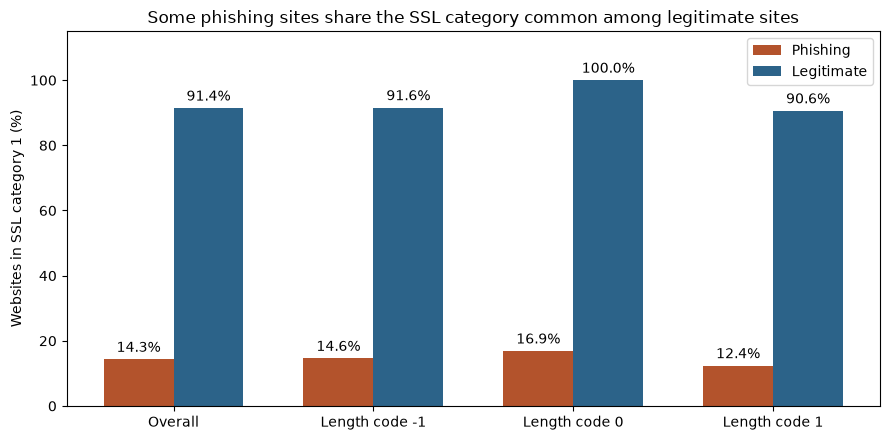

In [8]:
from pathlib import Path

rate = "percent_in_ssl_category_1"
labels = ["Overall", "Length code -1", "Length code 0", "Length code 1"]
x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 4.5))

for result, name, offset, color in [
    (-1, "Phishing", -width / 2, "#B3532C"),
    (1, "Legitimate", width / 2, "#2C6389"),
]:
    overall = ssl_rates.filter(pl.col("Result") == result)[rate].to_list()
    by_length = ssl_by_length.filter(pl.col("Result") == result)[rate].to_list()
    bars = ax.bar(x + offset, overall + by_length, width, label=name, color=color)
    ax.bar_label(bars, fmt="%.1f%%", padding=3)

ax.set_xticks(x, labels)
ax.set_ylabel("Websites in SSL category 1 (%)")
ax.set_ylim(0, 115)
ax.set_title("Some phishing sites share the SSL category common among legitimate sites")
ax.legend()
fig.tight_layout()

figure_dir = Path("../figures")
figure_dir.mkdir(exist_ok=True)
fig.savefig(figure_dir / "uci327-ssl-by-url-length.png", dpi=200, bbox_inches="tight")

plt.show()

## Legitimate-looking subdomain characteristics

For UCI 327, `having_Sub_Domain` is a publisher-defined category, not a numerical subdomain count. The code `1` means legitimate-looking, `0` means suspicious, and `-1` means phishing-looking. `Result = -1` identifies phishing websites and `Result = 1` identifies legitimate websites. I compare the share in subdomain category `1` overall and within the dataset's existing `URL_Length` categories (`-1`, `0`, and `1`).

In [9]:
def wilson_interval(successes, total, z=1.96):
    proportion = successes / total
    denominator = 1 + z**2 / total
    center = (proportion + z**2 / (2 * total)) / denominator
    half_width = (
        z
        * np.sqrt(proportion * (1 - proportion) / total + z**2 / (4 * total**2))
        / denominator
    )
    return 100 * (center - half_width), 100 * (center + half_width)

subdomain_records = []
for length_code, group_label in [
    (None, "Overall"),
    (-1, "URL length code -1"),
    (0, "URL length code 0"),
    (1, "URL length code 1"),
]:
    length_group = df if length_code is None else df.filter(pl.col("URL_Length") == length_code)
    for result, site_type in [(-1, "Phishing"), (1, "Legitimate")]:
        result_group = length_group.filter(pl.col("Result") == result)
        total = result_group.height
        count = result_group.filter(pl.col("having_Sub_Domain") == 1).height
        percent = 100 * count / total
        ci_low, ci_high = wilson_interval(count, total)
        subdomain_records.append({
            "group": group_label,
            "site_type": site_type,
            "legitimate_looking_count": count,
            "total": total,
            "percent": percent,
            "ci_low": ci_low,
            "ci_high": ci_high,
        })

subdomain_summary = pl.DataFrame(subdomain_records)
subdomain_summary.with_columns(
    pl.col("percent", "ci_low", "ci_high").round(2)
)

group,site_type,legitimate_looking_count,total,percent,ci_low,ci_high
str,str,i64,i64,f64,f64,f64
"""Overall""","""Phishing""",810,4898,16.54,15.52,17.6
"""Overall""","""Legitimate""",3260,6157,52.95,51.7,54.19
"""URL length code -1""","""Phishing""",682,4079,16.72,15.61,17.9
"""URL length code -1""","""Legitimate""",2610,4881,53.47,52.07,54.87
"""URL length code 0""","""Phishing""",9,83,10.84,5.81,19.34
"""URL length code 0""","""Legitimate""",25,52,48.08,35.1,61.31
"""URL length code 1""","""Phishing""",119,736,16.17,13.69,19.0
"""URL length code 1""","""Legitimate""",625,1224,51.06,48.26,53.85


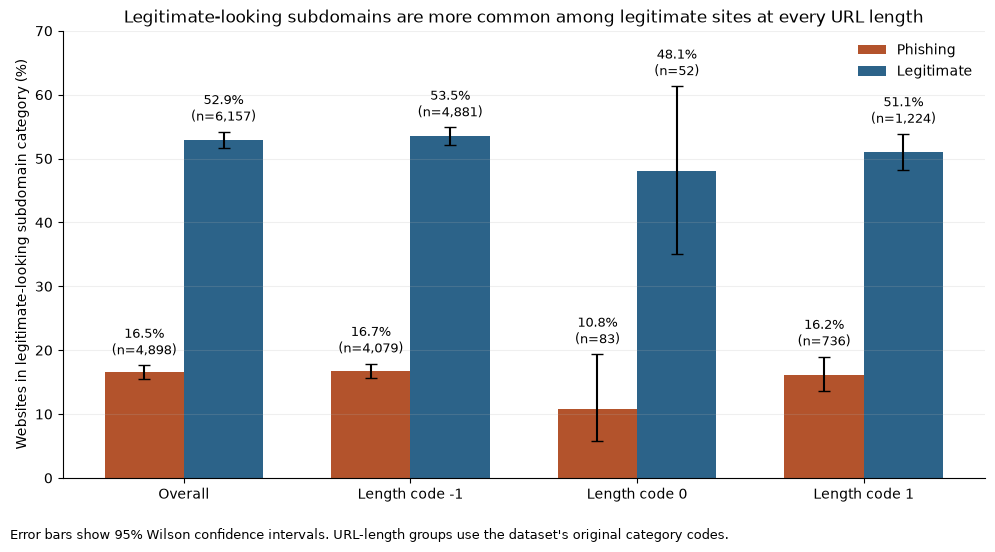

In [10]:
group_order = ["Overall", "URL length code -1", "URL length code 0", "URL length code 1"]
x = np.arange(len(group_order))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5.5))

for site_type, offset, color in [
    ("Phishing", -width / 2, "#B3532C"),
    ("Legitimate", width / 2, "#2C6389"),
]:
    rows = subdomain_summary.filter(pl.col("site_type") == site_type)
    percentages = rows["percent"].to_numpy()
    totals = rows["total"].to_numpy()
    lower_errors = percentages - rows["ci_low"].to_numpy()
    upper_errors = rows["ci_high"].to_numpy() - percentages
    bars = ax.bar(
        x + offset, percentages, width, label=site_type, color=color,
        yerr=np.vstack([lower_errors, upper_errors]), capsize=4,
    )
    ax.bar_label(
        bars,
        labels=[f"{percent:.1f}%\n(n={total:,})" for percent, total in zip(percentages, totals)],
        padding=5, fontsize=9,
    )

ax.set_xticks(x, ["Overall", "Length code -1", "Length code 0", "Length code 1"])
ax.set_ylabel("Websites in legitimate-looking subdomain category (%)")
ax.set_ylim(0, 70)
ax.set_title("Legitimate-looking subdomains are more common among legitimate sites at every URL length")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
fig.text(0.01, 0.01, "Error bars show 95% Wilson confidence intervals. URL-length groups use the dataset's original category codes.", fontsize=9)
fig.tight_layout(rect=[0, 0.05, 1, 1])

figure_dir = Path("../figures")
figure_dir.mkdir(exist_ok=True)
fig.savefig(figure_dir / "subdomain_comparison.png", dpi=200, bbox_inches="tight")

plt.show()

## Higher special-character ratios in phishing URLs

For the PhiUSIIL dataset, we can compare the special-character ratio of phishing and legitimate URLs. Because phishing URLs are usually longer, we can check whether the difference remains when URLs are compared within similar URL-length groups.

In [11]:
# load the phiUSILL data

phiusiil = pl.read_csv(
    "../datasets/PhiUSIIL_Phishing_URL_Dataset.csv",
    columns=["URLLength", "SpacialCharRatioInURL", "label"]
)

phiusiil.head()

URLLength,SpacialCharRatioInURL,label
i64,f64,i64
31,0.032,1
23,0.087,1
29,0.069,1
26,0.038,1
33,0.03,1


In [12]:
# create URL length groups

phiusiil = phiusiil.with_columns(
    pl.when(pl.col("URLLength") <= 25)
    .then(pl.lit("Short (25 or less)"))
    .when(pl.col("URLLength") <= 40)
    .then(pl.lit("Medium (26-40)"))
    .otherwise(pl.lit("Long (41+)"))
    .alias("length_group")
)

phiusiil.group_by(["length_group", "label"]).len().sort(
    ["length_group", "label"]
)

length_group,label,len
str,i64,u32
"""Long (41+)""",0,36066
"""Long (41+)""",1,798
"""Medium (26-40)""",0,40167
"""Medium (26-40)""",1,70060
"""Short (25 or less)""",0,24712
"""Short (25 or less)""",1,63992


In [13]:
# uncertainty:
# Pretend we sampled from this dataset again and again, calculate the median each time, then see how much the median moves

def bootstrap_median_ci(values, n_boot=300, seed=418):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)

    boot_medians = np.empty(n_boot)

    for i in range(n_boot):
        sample = rng.choice(values, size=len(values), replace=True)
        boot_medians[i] = np.median(sample)

    return np.percentile(boot_medians, [2.5, 97.5])

In [14]:
special_records = []

groups = [
    ("Overall", phiusiil),
    (
        "Short (≤25)",
        phiusiil.filter(pl.col("URLLength") <= 25)
    ),
    (
        "Medium (26–40)",
        phiusiil.filter(
            (pl.col("URLLength") > 25) &
            (pl.col("URLLength") <= 40)
        )
    ),
    (
        "Long (41+)",
        phiusiil.filter(pl.col("URLLength") > 40)
    ),
]

seed = 418

for group_name, group_df in groups:
    for label, site_type in [
        (0, "Phishing"),
        (1, "Legitimate")
    ]:
        values = (
            group_df
            .filter(pl.col("label") == label)
            .get_column("SpacialCharRatioInURL")
            .to_numpy()
        )

        median = np.median(values)

        ci_low, ci_high = bootstrap_median_ci(
            values,
            n_boot=300,
            seed=seed
        )

        special_records.append({
            "group": group_name,
            "site_type": site_type,
            "count": len(values),
            "median": median,
            "ci_low": ci_low,
            "ci_high": ci_high,
        })

        seed += 1

special_summary = pl.DataFrame(special_records)

special_summary.with_columns(
    pl.col("median", "ci_low", "ci_high").round(4)
)

group,site_type,count,median,ci_low,ci_high
str,str,i64,f64,f64,f64
"""Overall""","""Phishing""",100945,0.08,0.08,0.08
"""Overall""","""Legitimate""",134850,0.042,0.042,0.042
"""Short (≤25)""","""Phishing""",24712,0.05,0.05,0.05
"""Short (≤25)""","""Legitimate""",63992,0.045,0.045,0.045
"""Medium (26–40)""","""Phishing""",40167,0.077,0.077,0.077
"""Medium (26–40)""","""Legitimate""",70060,0.036,0.036,0.036
"""Long (41+)""","""Phishing""",36066,0.101,0.1,0.102
"""Long (41+)""","""Legitimate""",798,0.024,0.024,0.024


Overall: phishing URLs have almost twice the median special-character ratio.

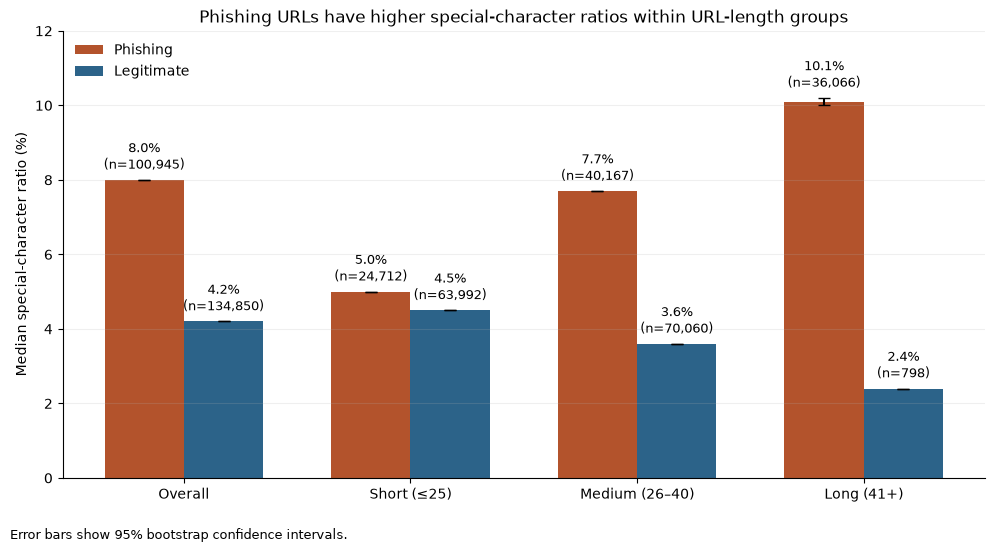

In [16]:
group_order = [
    "Overall",
    "Short (≤25)",
    "Medium (26–40)",
    "Long (41+)"
]

x = np.arange(len(group_order))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5.5))

for site_type, offset, color in [
    ("Phishing", -width / 2, "#B3532C"),
    ("Legitimate", width / 2, "#2C6389"),
]:
    rows = special_summary.filter(
        pl.col("site_type") == site_type
    )

    medians = rows["median"].to_numpy() * 100
    totals = rows["count"].to_numpy()

    ci_low = rows["ci_low"].to_numpy() * 100
    ci_high = rows["ci_high"].to_numpy() * 100

    lower_errors = medians - ci_low
    upper_errors = ci_high - medians

    bars = ax.bar(
        x + offset,
        medians,
        width,
        label=site_type,
        color=color,
        yerr=np.vstack([lower_errors, upper_errors]),
        capsize=4,
    )

    ax.bar_label(
        bars,
        labels=[
            f"{median:.1f}%\n(n={total:,})"
            for median, total in zip(medians, totals)
        ],
        padding=5,
        fontsize=9,
    )

ax.set_xticks(x, group_order)
ax.set_ylabel("Median special-character ratio (%)")
ax.set_title(
    "Phishing URLs have higher special-character ratios within URL-length groups"
)

ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
ax.set_ylim(0, 12)

fig.text(
    0.01,
    0.01,
    "Error bars show 95% bootstrap confidence intervals.",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.05, 1, 1])

figure_dir = Path("../figures")
figure_dir.mkdir(exist_ok=True)

fig.savefig(
    figure_dir / "phiusiil-special-character-ratio.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()